# Eight design steps, from the matplotlib default to the finished figure

**Kernel:** `python3`, the default Python (3.10 or newer) with labfigs and `scikit-learn` installed. Choose it before running.

**Shows:** the same scatter of iris sepal sizes eight times. Each panel adds one of Andrey Churkin's
design steps to the panel before it; the last panel is what labfigs gives by default.

**Graph type:** grid of scatter panels with fitted curves (`lf.points`, `lf.grid`, `lf.legend_above`).

**Writes:** `design_steps.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of the **Figure** cell and re-run that cell.

**To save:** run the one-line cell under a figure. It writes one file for each type in `FORMATS`, set in the
Setup cell: `("svg",)` by default, `("svg", "pdf", "png")` for all three. Nothing is written until that cell runs.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace design_steps.ipynb`, which also saves the figures in this notebook.

In [1]:
import matplotlib as mpl
import numpy as np
from sklearn.datasets import load_iris

import labfigs as lf

FORMATS = ("svg",)

## Data

Iris measurements from scikit-learn. `iris.data[:, :2]` holds sepal length and width in cm;
`iris.target` holds the species of each flower.

In [2]:
iris = load_iris()

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`, `PANEL_ASPECT`: figure width in inches, and the height of one panel divided by its width
- `FONT`, `SERIES`: text font, and the colour scheme that `C0`, `C1`, `C2` are taken from
- `STEPS`: title of each panel, in order
- `SPECIES`: one entry per species: its class, its colour before step 5, its colour from step 5 on
- `FITS`: one entry per fitted curve: polynomial degree, line style, legend entry, colour before step 5
- `X_LABEL`, `X_LIMITS`, `X_TICKS` and `Y_LABEL`, `Y_LIMITS`, `Y_TICKS`: the axes from step 2 on

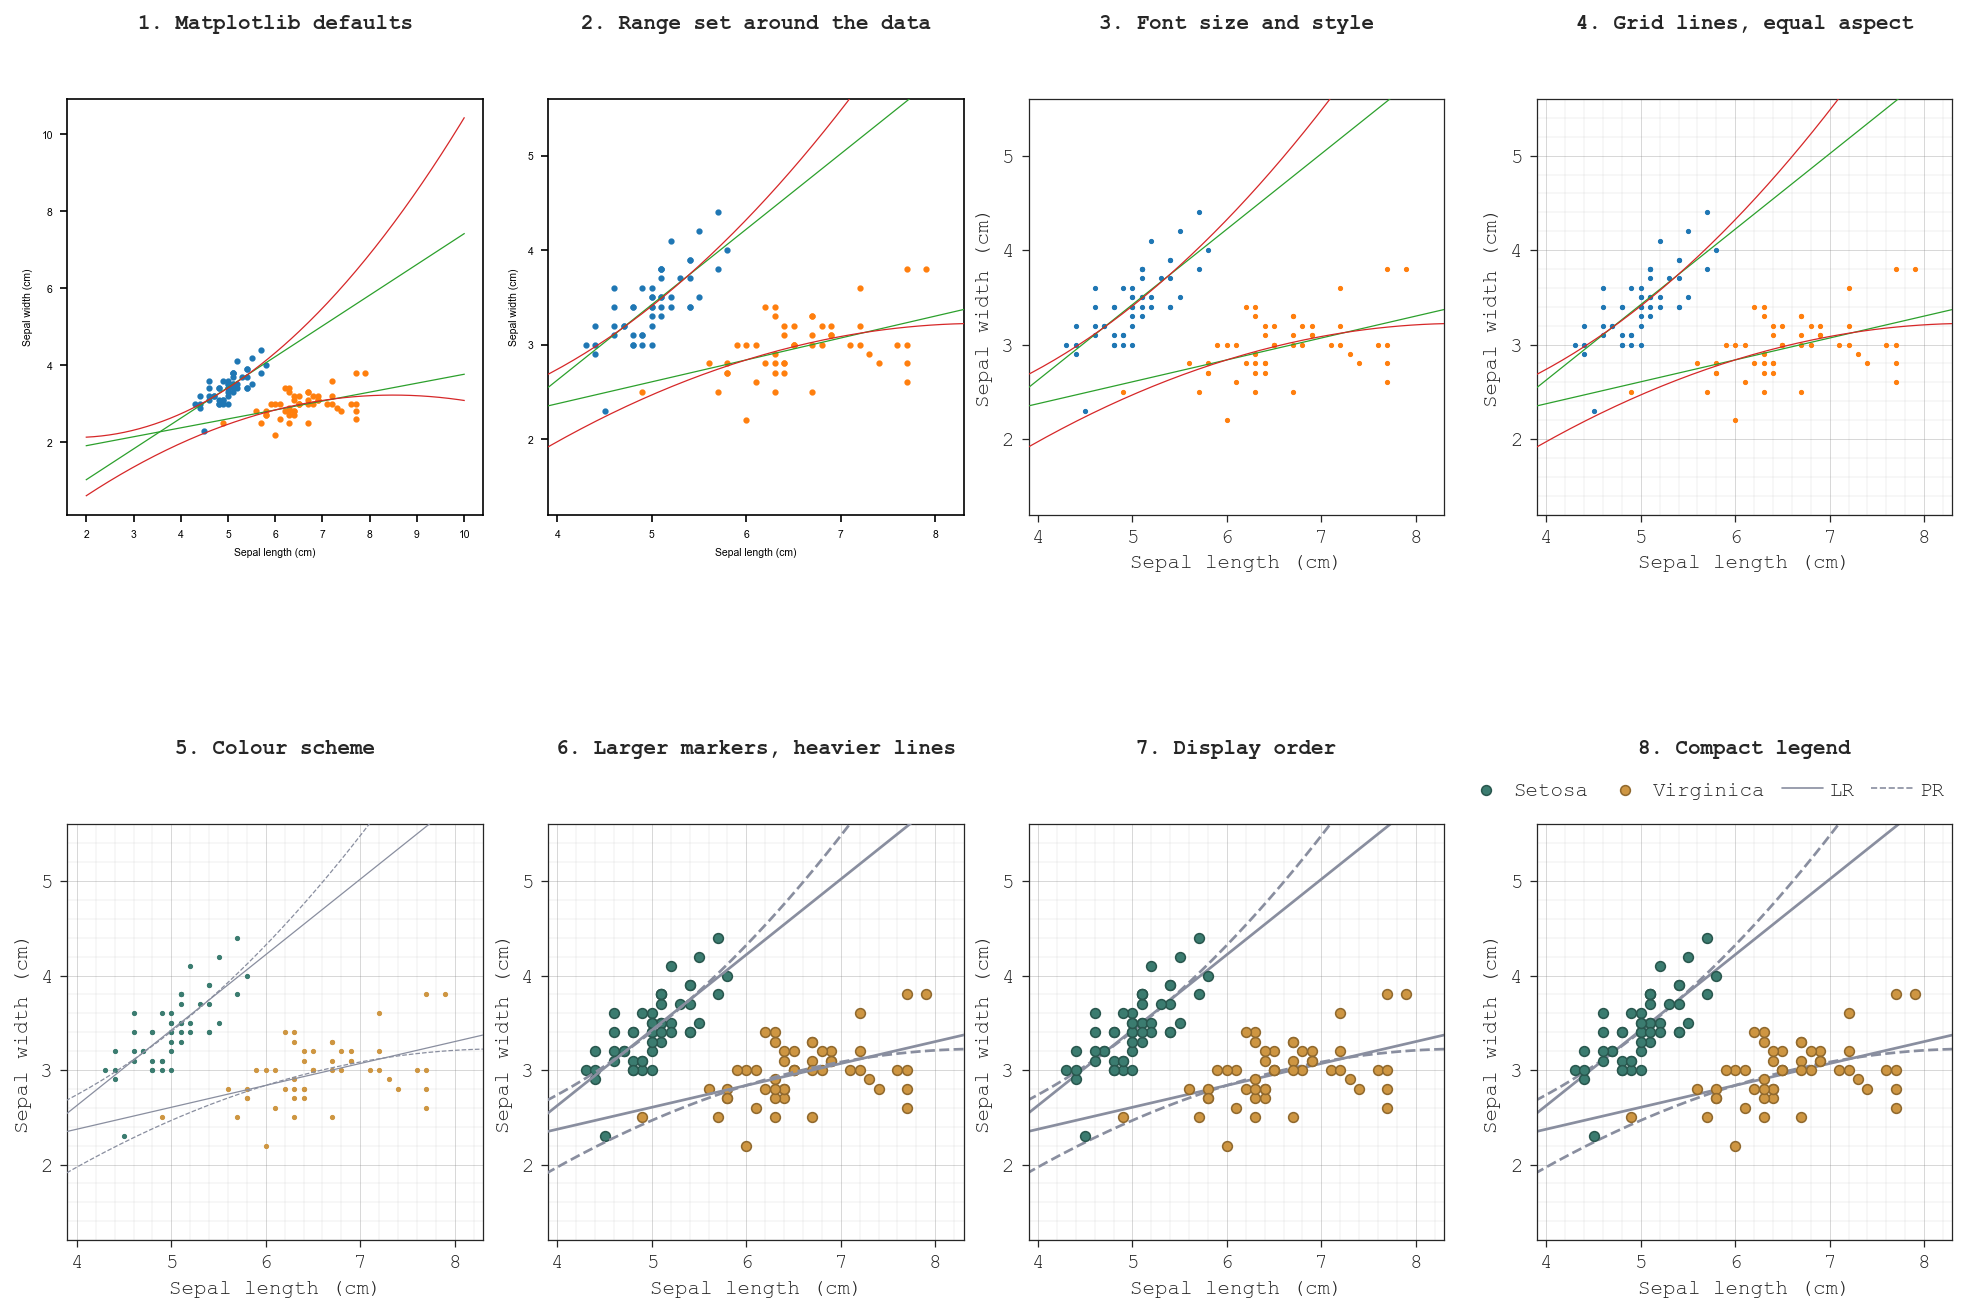

In [3]:
NAME = "design_steps"
WIDTH, PANEL_ASPECT = 13, 1.15
FONT, SERIES = "mono", "Kandinsky"
STEPS = ("Matplotlib defaults", "Range set around the data", "Font size and style", "Grid lines, equal aspect",
         "Colour scheme", "Larger markers, heavier lines", "Display order", "Compact legend")
SPECIES = ((0, "tab:blue", "C0"), (2, "tab:orange", "C1"))
FITS = ((1, "-", "LR", "tab:green"), (2, "--", "PR", "tab:red"))
X_LABEL, X_LIMITS, X_TICKS = "Sepal length (cm)", (3.9, 8.3), range(4, 9)
Y_LABEL, Y_LIMITS, Y_TICKS = "Sepal width (cm)", (1.2, 5.6), range(2, 6)

span = np.linspace(2, 10, 200)


def panel(ax, step):
    for kind, plain, color in SPECIES:
        x, y = iris.data[iris.target == kind, :2].T
        if step >= 5:
            lf.points(ax, x, y, color=color, label=iris.target_names[kind].title())
        else:
            ax.scatter(x, y, s=4, color=color if step >= 4 else plain)
    for kind, degree, style, label, bare in ((k, *fit) for k, *_ in SPECIES for fit in FITS):
        x, y = iris.data[iris.target == kind, :2].T
        look = dict(color="C2", ls=style) if step >= 4 else dict(color=bare)
        ax.plot(span, np.polyval(np.polyfit(x, y, degree), span), lw=1.3 if step >= 5 else 0.6,
                zorder=2 if step >= 6 else 4, label=label, **look)
    ax.set(xlabel=X_LABEL, ylabel=Y_LABEL, box_aspect=1)
    if step >= 1:
        ax.set(xlim=X_LIMITS, ylim=Y_LIMITS, xticks=X_TICKS, yticks=Y_TICKS)
    if step >= 3:
        lf.grid(ax)
        ax.set(aspect="equal")
    if step == 7:
        lf.legend_above(ax, gap=0.04, frameon=False, columnspacing=0.8, handletextpad=0.3)


lf.use(font=FONT, series=SERIES)
fig, axes = lf.subplots(2, 4, width=WIDTH, aspect=PANEL_ASPECT)
fig.get_layout_engine().set(hspace=0.16)
for step, ax in enumerate(axes.flat):
    if step < 2:
        ax.remove()
        # fixes the default look of the first two panels before the house style reaches them
        with mpl.rc_context(mpl.rcParamsDefault):
            ax = fig.add_subplot(2, 4, step + 1)
            panel(ax, step)
            ax.tick_params(labelsize=5)
            ax.xaxis.label.set_size(5)
            ax.yaxis.label.set_size(5)
            fig.canvas.draw()
    else:
        panel(ax, step)
    ax.text(0.5, 1.17, f"{step + 1}. {STEPS[step]}", transform=ax.transAxes, ha="center", weight="bold")
lf.show(fig, trim=False)

In [4]:
lf.save(fig, NAME, formats=FORMATS)

Saved design_steps.svg


## Checks

Fails if a panel is missing. Nothing to tweak.

In [5]:
assert len(fig.axes) == len(STEPS)